# 03 · Unsupervised models

* **Split by time**: train = days 0-60, validation = 60-70, test = 70-90.
* **Training never sees `is_fraud`.** Labels on the validation slice only pick hyper-parameters
  and the alert threshold; the test slice is only used for the final numbers.
* Detectors: z-score baseline (+ hard rules), Isolation Forest, Local Outlier Factor (novelty mode),
  One-Class SVM (on a 15k subsample, it scales badly), and a rank-average ensemble of the two best.
* Everything runs on a CPU; `make train` takes about a minute.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from kronos_ml.config import load_config, DATA_DIR, MODELS_DIR, REPORT_DIR
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
cfg = load_config()

In [2]:
from kronos_ml.models.train import load_features, split
parts = split(load_features(), cfg)
pd.DataFrame({k: {"rows": len(v), "fraud": int(v.is_fraud.sum()), "fraud_rate": round(v.is_fraud.mean(), 4),
                  "from": v.created_at.min().date(), "to": v.created_at.max().date()} for k, v in parts.items()}).T

,rows,fraud,fraud_rate,from,to
train,116941,2386,0.0204,2026-01-01,2026-03-01
val,18363,380,0.0207,2026-03-02,2026-03-11
test,37628,758,0.0201,2026-03-12,2026-03-31


In [3]:
tuning = pd.read_csv(MODELS_DIR / "tuning.csv")
tuning.sort_values(["family", "val_pr_auc"], ascending=[True, False]).round(3)

,family,params,val_pr_auc,fit_s
5,isolation_forest,"{""n_estimators"": 200, ""max_samples"": 2048, ""ma...",0.728,0.703
6,isolation_forest,"{""n_estimators"": 200, ""max_samples"": 2048, ""ma...",0.693,0.739
3,isolation_forest,"{""n_estimators"": 200, ""max_samples"": 1024, ""ma...",0.686,0.753
4,isolation_forest,"{""n_estimators"": 200, ""max_samples"": 1024, ""ma...",0.669,0.714
2,isolation_forest,"{""n_estimators"": 200, ""max_samples"": 256, ""max...",0.620,0.554
1,isolation_forest,"{""n_estimators"": 200, ""max_samples"": 256, ""max...",0.580,0.582
9,lof,"{""n_neighbors"": 250}",0.707,2.343
8,lof,"{""n_neighbors"": 100}",0.552,1.558
7,lof,"{""n_neighbors"": 20}",0.063,1.033
14,ocsvm,"{""nu"": 0.1, ""gamma"": ""scale""}",0.674,2.738


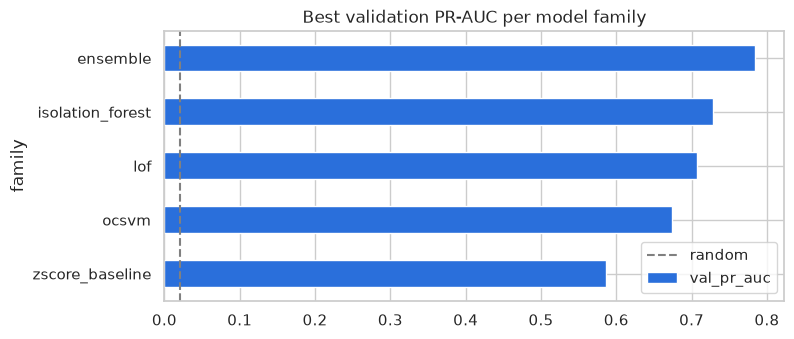

In [4]:
best = tuning.loc[tuning.groupby("family").val_pr_auc.idxmax()].set_index("family").val_pr_auc
card = json.loads((MODELS_DIR / "model_card.json").read_text())
best["ensemble"] = card["validation_pr_auc"]["ensemble"]
ax = best.sort_values().plot.barh(figsize=(8, 3.5), color="#2a6fdb", title="Best validation PR-AUC per model family")
ax.axvline(parts["val"].is_fraud.mean(), ls="--", color="grey", label="random"); ax.legend();

In [5]:
print(json.dumps({k: card[k] for k in ["version", "model", "description", "thresholds", "labels_used_for_training"]}, indent=2))

{
  "version": "ensemble-20261122081923",
  "model": "ensemble",
  "description": "ensemble(isolation_forest + lof)",
  "thresholds": {
    "medium_score": 0.5,
    "high_score": 0.8,
    "medium_raw": 0.8547520000000001,
    "high_raw": 0.9402174999999999,
    "medium_alert_rate": 0.08,
    "high_alert_rate": 0.030005990306594784
  },
  "labels_used_for_training": false
}


### Choosing the High (hold) threshold: business cost on validation

,alert_rate,threshold,missed_fraud_amount,caught_fraud_amount,alerts,review_cost,total_cost
0,0.0,1.0,73493.8,2399.2,92,1380.0,74873.8
1,0.0,1.0,61256.7,14636.2,138,2070.0,63326.7
2,0.0,1.0,34663.6,41229.3,184,2760.0,37423.6
3,0.0,1.0,16869.0,59023.9,276,4140.0,21009.0
4,0.0,1.0,12369.2,63523.7,368,5520.0,17889.2
5,0.0,0.9,7493.6,68399.3,551,8265.0,15758.6
6,0.0,0.9,5080.1,70812.9,735,11025.0,16105.1
7,0.0,0.9,3961.8,71931.1,919,13785.0,17746.8


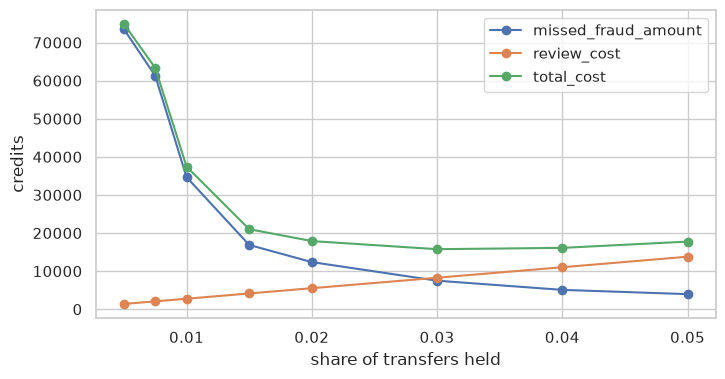

In [6]:
grid = pd.read_csv(MODELS_DIR / "threshold_cost.csv")
display(grid.round(1))
ax = grid.plot(x="alert_rate", y=["missed_fraud_amount", "review_cost", "total_cost"], marker="o", figsize=(8, 4))
ax.set(xlabel="share of transfers held", ylabel="credits");

Cost = fraud money that settles because we missed it + a fixed analyst cost per alert
(`risk.review_cost` in `config.yaml`). The minimum sets how much traffic a bank-style desk should review.